# CP2/CP3 – Fine-tuning LoRA em GPU NVIDIA (Colab)

Este notebook roda o projeto inteiro em uma **GPU NVIDIA com CUDA** do Google Colab, para quem não tem GPU NVIDIA local.

**Como usar no VSCode:** instale a extensão **Google Colab** (publisher: Google) e a extensão Jupyter, abra este arquivo, clique em **Select Kernel → Colab** e escolha um runtime com GPU (faça login com a conta Google). No navegador (colab.research.google.com), use *Ambiente de execução → Alterar tipo → GPU*.

Execute as células **em ordem**. A GPU gratuita não é garantida: confira o nome da placa na primeira célula.

## 1. Conferir a GPU (print de evidência)

In [1]:
!nvidia-smi
import torch
print("CUDA disponível:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0), "| CUDA", torch.version.cuda, "| PyTorch", torch.__version__)
else:
    raise SystemExit("Sem GPU: troque o runtime/kernel para um com GPU e rode de novo.")

Fri Oct 16 00:45:23 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA A100-SXM4-80GB          Off |   00000000:00:05.0 Off |                    0 |
| N/A   35C    P0             50W /  400W |       0MiB /  81920MiB |      0%      Default |
|                                         |                        |             Disabled |
+-----------------------------------------+-----

## 2. Baixar o código do GitHub

Troque `REPO_URL` pelo link do repositório do grupo (suba o código para o GitHub antes). Se o repositório for privado, use um token: `https://<TOKEN>@github.com/usuario/repo.git` (não commite o token).

In [2]:
REPO_URL = "https://github.com/JBVJoaoV/CP5_6_GenIA.git"   
import os
REPO_DIR = REPO_URL.rstrip("/").split("/")[-1].removesuffix(".git")
if not os.path.exists(REPO_DIR):
    !git clone {REPO_URL}
%cd {REPO_DIR}
!ls

Cloning into 'CP5_6_GenIA'...
remote: Enumerating objects: 25, done.
remote: Counting objects: 100% (25/25), done.
remote: Compressing objects: 100% (19/19), done.
remote: Total 25 (delta 2), reused 25 (delta 2), pack-reused 0 (from 0)
Receiving objects: 100% (25/25), 31.01 KiB | 31.01 MiB/s, done.
Resolving deltas: 100% (2/2), done.
/content/CP5_6_GenIA
data  docs  notebooks  README.md  requirements.txt  src


## 3. Instalar dependências
O PyTorch com CUDA já vem instalado no Colab; aqui entram só as demais bibliotecas.

In [3]:
!pip install -q -r requirements.txt
# O Colab traz um torchao antigo que o PEFT rejeita (ImportError). Não usamos torchao, então removemos.
!pip uninstall -y -q torchao

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.0/44.0 kB 4.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 146.4 MB/s eta 0:00:0000:010:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 32.3/32.3 MB 83.0 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 60.0/60.0 kB 7.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 566.4/566.4 kB 51.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.3/3.3 MB 124.9 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
diffusers 0.40.0 requires huggingface-hub<2.0,>=1.23.0, but you have huggingface-hub 0.36.2 which is incompatible.


## 4. Teste de GPU do projeto

In [4]:
!python src/check_gpu.py

PyTorch: 2.11.0+cu130
CUDA (compilado no PyTorch): 13.0
CUDA disponível: True
GPU: NVIDIA A100-SXM4-80GB
VRAM total: 79.3 GB
Compute capability: 8.0
bf16 suportado: True
matmul 4096x4096: CPU 236 ms | GPU (fp16) 0.6 ms | speedup ~429x
Fri Oct 16 00:45:56 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA A100-SXM4-80GB          Off |   00000000:00:05.0 Off |                    0

## 5. Preparar os dados

In [5]:
!python src/prepare_data.py

train: 188 exemplos -> /content/CP5_6_GenIA/data/train.jsonl
val: 12 exemplos -> /content/CP5_6_GenIA/data/val.jsonl


## 6. Modelo base vs. um treino de teste

Se der `out of memory`, troque o modelo por `Qwen/Qwen2.5-0.5B-Instruct` em **todas** as células (`--model`).

In [6]:
MODEL = "Qwen/Qwen2.5-1.5B-Instruct"   # ou "Qwen/Qwen2.5-0.5B-Instruct" se faltar memória
!rm -rf results outputs   # limpa resultados de execuções anteriores
!python src/evaluate.py --tag base --model {MODEL}
!python src/train.py --name baseline --model {MODEL}
!python src/evaluate.py --adapter outputs/baseline/adapter --tag baseline --model {MODEL}

tokenizer_config.json: 7.30kB [00:00, 26.4MB/s]
vocab.json: 2.78MB [00:00, 125MB/s]
merges.txt: 1.67MB [00:00, 133MB/s]
tokenizer.json: 7.03MB [00:00, 196MB/s]
config.json: 100% 660/660 [00:00<00:00, 6.70MB/s]
`torch_dtype` is deprecated! Use `dtype` instead!
I0000 00:00:1792111573.858281    6287 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1792111573.926323    6287 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1792111576.507191    6287 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floa

## 7. Bateria de experimentos (diferentes parâmetros)

Use `--quick` para a versão rápida (3 configurações). Sem `--quick` roda as 7 configurações e o teste de temperatura. Se a sessão cair, rode de novo: o que já foi salvo em `results/` é regenerado.

In [7]:
!python src/run_experiments.py --quick --model {MODEL}


>>> /content/CP5_6_GenIA/src/prepare_data.py
train: 188 exemplos -> /content/CP5_6_GenIA/data/train.jsonl
val: 12 exemplos -> /content/CP5_6_GenIA/data/val.jsonl

>>> /content/CP5_6_GenIA/src/evaluate.py --tag base --model Qwen/Qwen2.5-1.5B-Instruct
`torch_dtype` is deprecated! Use `dtype` instead!
I0000 00:00:1792111914.818932    7980 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1792111914.887796    7980 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1792111917.462287    7980 port.cc:153] oneDNN custom operations are on. You may see slightl

## 8. Gráficos e tabelas de resultados

Gráficos salvos em /content/CP5_6_GenIA/docs/img


,name,lora_r,lr,epochs,train_loss,eval_loss,perplexity,train_seconds,peak_vram_gb,token_f1,structure,tokens_per_s
0,baseline,8,0.0002,3.0,1.236089,1.843670,6.319689,41.5,9.52,0.4397,1.0,13.7
1,r16,16,0.0002,3.0,0.977995,2.118343,8.317347,40.3,9.67,0.4111,1.0,13.6
2,lr5e-4,8,0.0005,3.0,0.746356,2.615886,13.679334,41.5,9.52,0.4087,1.0,13.2


,temperature,token_f1,structure,tokens_per_s
0,0.0,0.4397,1.0,13.8
1,0.3,0.4292,1.0,13.5
2,0.7,0.3939,1.0,13.1
3,1.0,0.3729,1.0,13.3


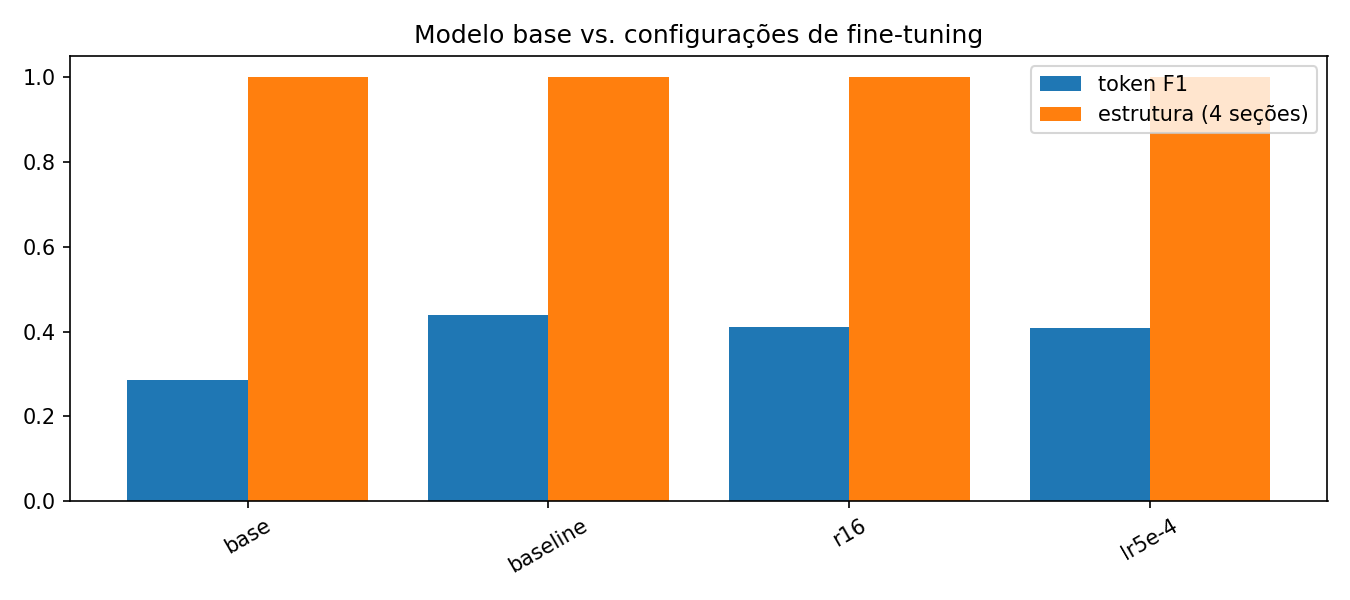

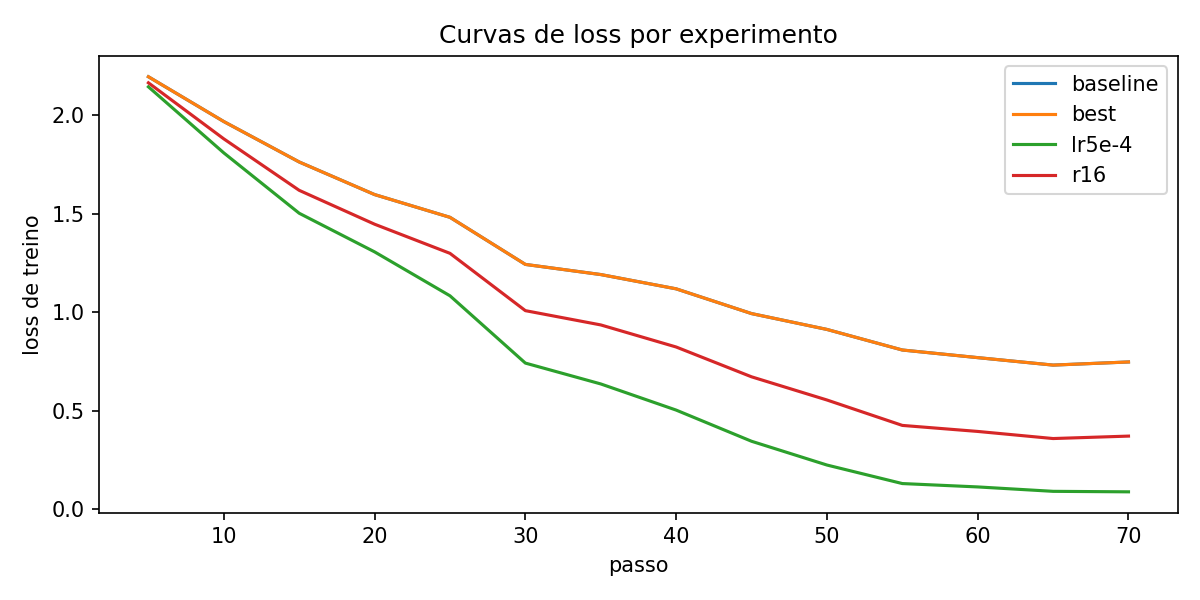

In [8]:
!python src/plot_results.py
import pandas as pd
from IPython.display import Image, display
display(pd.read_csv("results/experiments.csv"))
display(pd.read_csv("results/gen_sweep.csv"))
display(Image("docs/img/experimentos_f1.png"))
display(Image("docs/img/curvas_loss.png"))

## 9. Respostas para a análise qualitativa

Compare o modelo base com o fine-tuned (cole 2–3 exemplos no README).

In [9]:
base = pd.read_csv("results/eval_base.csv")
best = pd.read_csv("results/eval_best_T0.0.csv")
for i in range(3):
    print("="*80); print("RELATO:", base.instruction[i])
    print("\n--- BASE ---\n", base.prediction[i])
    print("\n--- FINE-TUNED ---\n", best.prediction[i])
    print("\n--- REFERÊNCIA ---\n", base.reference[i])

RELATO: A IHM perdeu a comunicação com o CLP e mostra falha de timeout em intervalos.

--- BASE ---
 Causa provável:
O problema pode ser causado por uma interrupção no sinal de dados entre o Controlador Local do Processamento (CLP) e a Interface Humana Modular (IHM). Isso poderia ocorrer por falta de energia elétrica, problemas de conexão ou mesmo por falhas nos componentes eletrônicos.

Verificações:
1. Verifique a corrente fornecida ao sistema.
2. Confirme que a rede está funcionando normalmente.
3. Verifique as conexões físicas entre o CLP e a IHM.
4. Teste a conectividade remota entre os dois dispositivos.

Ação recomendada:
Se possível, forneça mais energia à máquina para garantir que ela esteja sempre ligada. Caso contrário, verifique a conexão física e a integridade dos componentes da rede. Se houver algum componente defeituoso, substitua-o.

Segurança:
Antes de realizar qualquer reparo, certifique-se de que não há ninguém trabalhando na área. Use roupas adequadas e equipamentos

## 10. Frontend (Gradio)

Roda o app com link público (`--share`). Abra o link `https://....gradio.live` que aparecer, teste um relato e tire o print. Para encerrar, interrompa a célula.

In [12]:
!python src/app.py --share --model {MODEL}

`torch_dtype` is deprecated! Use `dtype` instead!
I0000 00:00:1792113459.860251   15549 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1792113459.928712   15549 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1792113462.600847   15549 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1792113462.601417   15549 cudart_stub.cc:31] Could not find c

## 11. Salvar os resultados

Os arquivos de `results/` e `docs/img/` precisam ir para o repositório. Duas opções: (a) baixar o zip abaixo; (b) copiar para o Google Drive. Depois coloque as pastas no repositório e dê commit.

In [15]:
!zip -qr resultados.zip results docs/img
try:
    from google.colab import files
    files.download("resultados.zip")
except Exception as e:
    print("Download automático indisponível aqui:", e)
    try:
        from google.colab import drive
        drive.mount("/content/drive")
        !mkdir -p /content/drive/MyDrive/cp2_resultados && cp -r results docs/img /content/drive/MyDrive/cp2_resultados/
        print("Copiado para o Google Drive: cp2_resultados")
    except Exception as e2:
        print("Drive indisponível:", e2, "- copie o conteúdo exibido nas células acima.")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [14]:
import json
b = json.load(open("results/eval_base.json"))
print(f"| base (sem fine-tuning) | {b['token_f1']:.4f} | {b['structure']:.2f} | – | – | – | – | – |".replace(".", ","))
print("F1 base:", f"{b['token_f1']:.4f}".replace(".", ","), "| estrutura:", b["structure"])

| base (sem fine-tuning) | 0,2853 | 1,00 | – | – | – | – | – |
F1 base: 0,2853 | estrutura: 1.0


In [16]:
from google.colab import drive
drive.mount("/content/drive")
!mkdir -p /content/drive/MyDrive/cp2_resultados && cp -r results docs/img /content/drive/MyDrive/cp2_resultados/

Mounted at /content/drive
